In [69]:
#Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import missingno as msno

In [70]:
# Set up path to the data file and read it into a DataFrame
notebook_path = Path.cwd()
project_path = notebook_path.parent
data_path = project_path / "data" / "processed" / "raw_master_table.csv"
df = pd.read_csv(data_path)

# Fixing data types (seqn to be int (there is no NULL), categorical columns to be 'Int64' (so it doesn't convert to float again after a NULL))
df['seqn'] = df['seqn'].astype(int)

cat_cols=[
    "sex",
    "military_service",
    "education",
    "firearm_and_protection",
    "firearm_exposure_level",
    "loud_noise",
    "very_loud_noise",
    "heart_disease",
    "heart_attack",
    "stroke",
    "cancer",
    "diabetes",
    "hl_presence",
    "hl_severity",
]
df[cat_cols]= df[cat_cols].astype('Int64')

#Checking the NULL data percentage in each column
missing_pct = df.isnull().mean().sort_values(ascending=False) * 100
print(missing_pct)

very_loud_noise           67.138547
lead                      52.100255
cadmium                   52.100255
income_poverty_ratio       8.888373
blood_pressure             1.972615
bmi                        0.580181
firearm_exposure_level     0.533767
heart_disease              0.255280
firearm_and_protection     0.139243
loud_noise                 0.092829
cancer                     0.069622
stroke                     0.046414
heart_attack               0.046414
diabetes                   0.046414
education                  0.000000
age                        0.000000
sex                        0.000000
seqn                       0.000000
military_service           0.000000
hl_presence                0.000000
hl_severity                0.000000
dtype: float64


After checking the codebook, I realized very_loud_noise was NULL for every person who answered "no" to loud_noise question. So in the imputation phase, 
we can choose "no" for this column when very_oud_noise value is NULL and its corresponding loud_noise is "no". Because the NULL percentage is very high, it will affect our eda visulizations on the data distribution, so I will do this imputation now (instead of after EDA in the cleaning phase):

In [71]:
df.loc[(df['loud_noise'] == 1) & (df['very_loud_noise'].isnull()), 'very_loud_noise'] = 1

<Axes: >

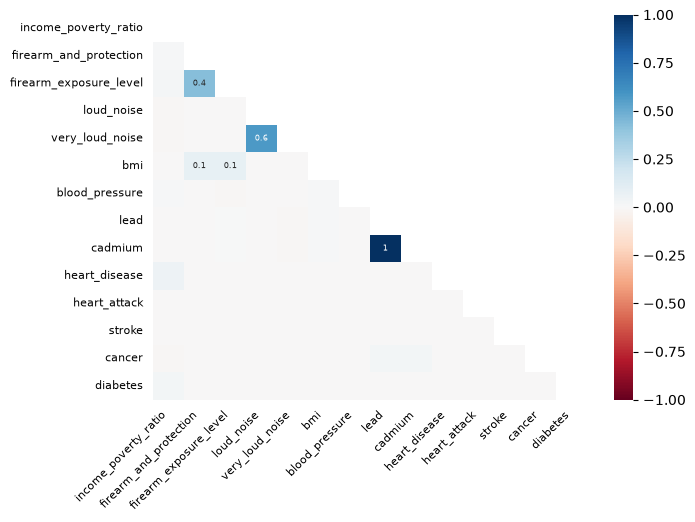

In [96]:
#Correlation for NULL 
msno.heatmap(df,figsize=(7, 5), fontsize= 8)

The figure shows the correlation between features on NULL values. Based on the codebook and this figure, Lead and Cadmium used a same blood sample test
and its presence was randomized on nearly half of the subjects, so they are both NULL at the same time. 
As for 0.6 and 0.4 correlations, both 2 groups of questions (firearm usage and noise in work) are asked within the same section, so a person who skips the first one is likely to skip the second one.

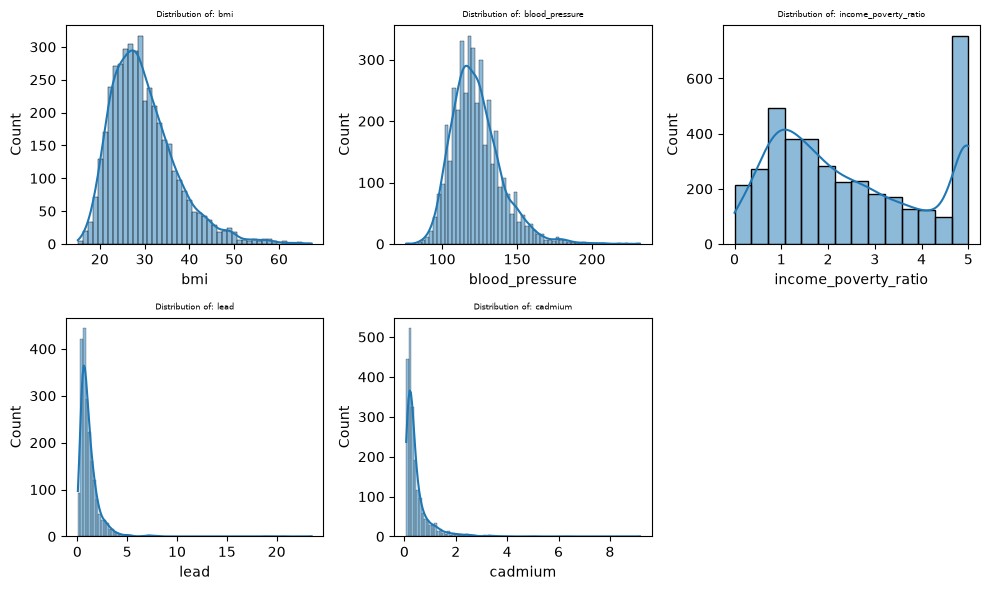

In [73]:
# Distribution on continuous features
continuous_features = ['bmi', 'blood_pressure', 'income_poverty_ratio', 'lead', 'cadmium']
fig, axes = plt.subplots (nrows= 2, ncols= 3, figsize= (10, 6))
axes = axes.flatten()

for i, col in enumerate(continuous_features):
    sns.histplot(data= df, x=col, kde= True, ax= axes[i])
    axes[i].set_title(f'Distribution of: {col}', fontsize = 6)

# Removing empty plot:
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Lead & Cadmium : They are heavily right skewed, so we use median instead of mean for imputation as it is more close to the majority.
Income poverty ratio: There is a spike in column 5. The reason is that all incomes higher than level 5 are labeled as 5 by NHANES. I will use Median for this as well.
BMI & Blood Pressure: Pretty normal, I will use Median for imputation.

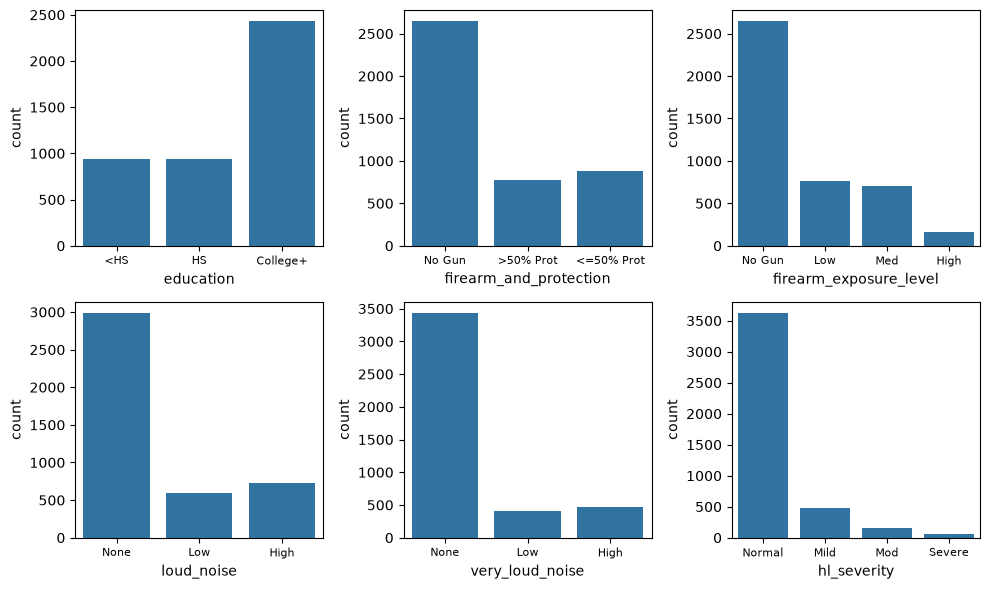

In [112]:
# Distribution on Ordinal Features
ordinal_features= ['education', 'firearm_and_protection', 'firearm_exposure_level', 'loud_noise', 'very_loud_noise', 'hl_severity']
labels = {
    'education': ['<HS', 'HS', 'College+'],
    'firearm_and_protection': ['No Gun', '>50% Prot', '<=50% Prot'],
    'firearm_exposure_level': ['No Gun', 'Low', 'Med', 'High'],
    'loud_noise': ['None', 'Low', 'High'],
    'very_loud_noise': ['None', 'Low', 'High'],
    'hl_severity': ['Normal', 'Mild', 'Mod', 'Severe']
}

fig, axes = plt.subplots (nrows= 2, ncols= 3, figsize= (10, 6))
axes = axes.flatten()

for i, col in enumerate(ordinal_features):
    sns.countplot(data= df, x= col, ax= axes[i])
    axes[i].set_xticks(range(len(labels[col])))
    axes[i].set_xticklabels(labels[col], fontsize = 8)

plt.tight_layout()
plt.show()

Before plotting the binary features, I realized I coded the values in (1, 2). I am going to map them first to (0, 1) right now as it makes it easier to use functions like mean() on them. 

In [ ]:
#Remapping to (0, 1), but in a way so when the code block is run more than once, we are not going to have 0 for every row.
binary_cols = ['sex', 'military_service', 'heart_disease', 'heart_attack', 'stroke', 'cancer', 'diabetes']
for col in binary_cols:
    if (df[col] == 2).any():
        df[col] = df[col].replace({1: 0, 2: 1})

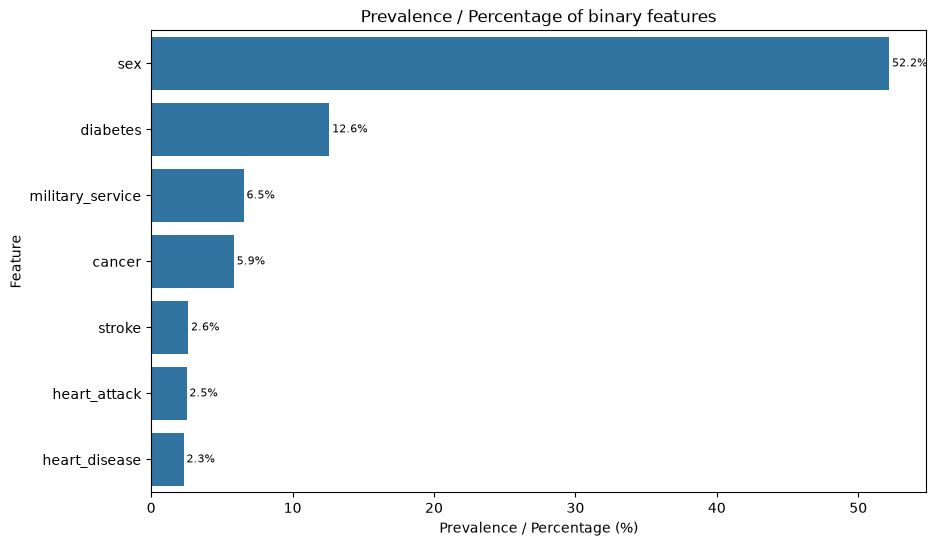

In [105]:
prevalence = df[binary_cols].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 6))
ax= sns.barplot(x=prevalence.values, y=prevalence.index, orient='h')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=2, fontsize= 8)
plt.xlabel('Prevalence / Percentage (%)')
plt.ylabel('Feature')
plt.title('Prevalence / Percentage of binary features')
plt.show()


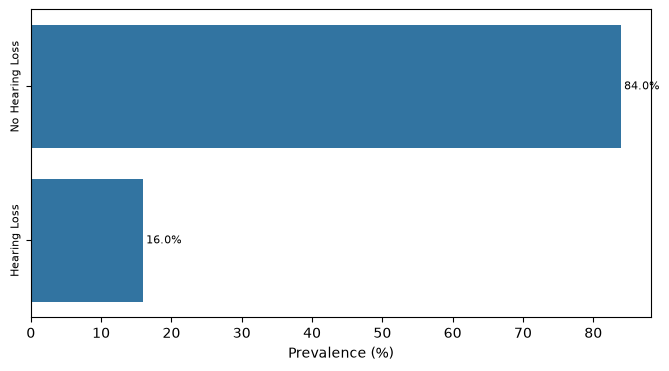

In [144]:
pct = df['hl_presence'].value_counts(normalize= True) * 100

plt.figure(figsize=(8, 4))
ax= sns.barplot(x= pct.values, y= ['No Hearing Loss', 'Hearing Loss'],  orient='h')
plt.yticks(rotation=90, fontsize= 8, va='center')
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=2, fontsize= 8)
plt.xlabel('Prevalence (%)')
plt.show()